<a href="https://colab.research.google.com/github/Nageshwar9784/MTech-AI-Data-Science/blob/main/FRIEND_Colab_Train.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# FRIEND Cross-Dataset Pneumonia Project

This notebook trains two MobileNetV2 models and performs four evaluations: A-on-A, A-on-B, B-on-B, and B-on-A. It saves checkpoints, metrics, figures, `run_log.csv`, and a continuously updated `progress.json` to Google Drive.

Before running, choose **Runtime > Change runtime type > GPU**. The first Drive-mount prompt must be approved by the account owner.


In [1]:
!pip -q install kagglehub
import torch
print('PyTorch:', torch.__version__)
print('GPU available:', torch.cuda.is_available())
if torch.cuda.is_available():
    print('GPU:', torch.cuda.get_device_name(0))


PyTorch: 2.14.1+cu130
GPU available: True
GPU: Tesla T4


In [2]:
import csv
import hashlib
import json
import os
import random
import threading
import time
import traceback
from datetime import datetime, timezone
from pathlib import Path

import kagglehub
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from PIL import Image
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, f1_score
from torch.cuda.amp import GradScaler, autocast
from torch.utils.data import DataLoader, Dataset
from torchvision import models, transforms


SEED = 42
SAMPLES_PER_CLASS = 1200
EPOCHS = 5
IMAGE_SIZE = 224
HEARTBEAT_SECONDS = 30 * 60


def utc_now():
    return datetime.now(timezone.utc).isoformat(timespec="seconds")


def atomic_json(path, payload):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    tmp = path.with_suffix(path.suffix + ".tmp")
    tmp.write_text(json.dumps(payload, indent=2), encoding="utf-8")
    tmp.replace(path)


class ProgressTracker:
    def __init__(self, root):
        self.root = Path(root)
        self.path = self.root / "progress.json"
        self.started = time.time()
        self.lock = threading.Lock()
        self.stop_event = threading.Event()
        self.state = {
            "project": "FRIEND chest X-ray project",
            "status": "starting",
            "stage": "initializing",
            "detail": "Colab pipeline is starting",
            "overall_percent": 0,
            "completed_steps": [],
            "remaining_steps": [
                "download datasets", "prepare balanced splits", "train model A",
                "evaluate A on A and B", "train model B", "evaluate B on B and A",
                "selective prediction", "export figures and summary"
            ],
            "heartbeat_interval_minutes": 30,
            "updated_at_utc": utc_now(),
        }
        self.write()
        self.thread = threading.Thread(target=self._heartbeat, daemon=True)
        self.thread.start()

    def write(self):
        with self.lock:
            self.state["updated_at_utc"] = utc_now()
            self.state["elapsed_minutes"] = round((time.time() - self.started) / 60, 1)
            atomic_json(self.path, self.state)

    def update(self, stage, detail, percent, status="running", completed=None, remaining=None, **extra):
        with self.lock:
            self.state.update({
                "stage": stage,
                "detail": detail,
                "overall_percent": round(float(percent), 1),
                "status": status,
                "updated_at_utc": utc_now(),
                "elapsed_minutes": round((time.time() - self.started) / 60, 1),
            })
            if completed is not None:
                self.state["completed_steps"] = completed
            if remaining is not None:
                self.state["remaining_steps"] = remaining
            self.state.update(extra)
            atomic_json(self.path, self.state)
        print(f"[{self.state['overall_percent']:5.1f}%] {stage}: {detail}")

    def _heartbeat(self):
        while not self.stop_event.wait(HEARTBEAT_SECONDS):
            self.write()
            print(f"[heartbeat] {self.state['overall_percent']}% - {self.state['stage']}")

    def finish(self, detail):
        self.update("complete", detail, 100, status="complete", remaining=[])
        self.stop_event.set()

    def fail(self, exc):
        self.update("failed", str(exc), self.state.get("overall_percent", 0), status="failed",
                    error=traceback.format_exc())
        self.stop_event.set()


class XrayDataset(Dataset):
    def __init__(self, samples, transform):
        self.samples = samples
        self.transform = transform

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, idx):
        path, label, domain = self.samples[idx]
        with Image.open(path) as image:
            image = image.convert("RGB")
            image = self.transform(image)
        return image, label, str(path), domain


def image_files(folder):
    valid = {".jpg", ".jpeg", ".png", ".bmp"}
    return sorted(p for p in Path(folder).rglob("*") if p.suffix.lower() in valid)


def normalized_image_hash(path):
    with Image.open(path) as image:
        image = image.convert("L").resize((64, 64), Image.Resampling.BILINEAR)
        pixels = np.asarray(image, dtype=np.uint8)
    return hashlib.sha256(pixels.tobytes()).hexdigest()


def remove_cross_dataset_duplicates(a_files, b_files, tracker, start_pct=18, end_pct=24):
    a_hashes = set()
    total = len(a_files) + len(b_files)
    checked = 0
    corrupt = []
    for path in a_files:
        try:
            a_hashes.add(normalized_image_hash(path))
        except Exception as exc:
            corrupt.append({"path": str(path), "error": str(exc)})
        checked += 1
        if checked % 1000 == 0:
            tracker.update("duplicate_check", f"Checked {checked}/{total} images",
                           start_pct + (end_pct - start_pct) * checked / total)
    clean, excluded = [], []
    for path in b_files:
        try:
            if normalized_image_hash(path) in a_hashes:
                excluded.append(path)
            else:
                clean.append(path)
        except Exception as exc:
            corrupt.append({"path": str(path), "error": str(exc)})
        checked += 1
        if checked % 1000 == 0 or checked == total:
            tracker.update("duplicate_check", f"Checked {checked}/{total} images",
                           start_pct + (end_pct - start_pct) * checked / total)
    return clean, excluded, corrupt


def find_dir(root, required_parts):
    required = [part.lower() for part in required_parts]
    matches = []
    for path in Path(root).rglob("*"):
        if not path.is_dir():
            continue
        parts = [part.lower() for part in path.parts]
        if len(parts) >= len(required) and parts[-len(required):] == required:
            matches.append(path)
    if not matches:
        raise FileNotFoundError(f"Could not find directory ending in {required_parts} below {root}")
    return min(matches, key=lambda p: len(p.parts))


def balanced_split(class0, class1, domain, limit=SAMPLES_PER_CLASS):
    rng = random.Random(SEED)
    c0, c1 = list(class0), list(class1)
    rng.shuffle(c0)
    rng.shuffle(c1)
    n = min(limit, len(c0), len(c1))
    if n < 100:
        raise RuntimeError(f"Too few images for {domain}: {len(c0)} and {len(c1)}")
    c0, c1 = c0[:n], c1[:n]
    cut = int(0.8 * n)
    train = [(p, 0, domain) for p in c0[:cut]] + [(p, 1, domain) for p in c1[:cut]]
    test = [(p, 0, domain) for p in c0[cut:]] + [(p, 1, domain) for p in c1[cut:]]
    rng.shuffle(train)
    rng.shuffle(test)
    return train, test


def build_model(device):
    model = models.mobilenet_v2(weights=models.MobileNet_V2_Weights.IMAGENET1K_V1)
    for param in model.features.parameters():
        param.requires_grad = False
    model.classifier[1] = nn.Linear(model.last_channel, 2)
    return model.to(device)


def unfreeze_tail(model):
    for block in list(model.features.children())[-4:]:
        for param in block.parameters():
            param.requires_grad = True


def make_loaders(train_samples, test_samples, batch_size, workers):
    train_tf = transforms.Compose([
        transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
        transforms.RandomHorizontalFlip(),
        transforms.RandomRotation(7),
        transforms.ToTensor(),
        transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225]),
    ])
    test_tf = transforms.Compose([
        transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
        transforms.ToTensor(),
        transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225]),
    ])
    common = dict(batch_size=batch_size, num_workers=workers, pin_memory=torch.cuda.is_available())
    train_loader = DataLoader(XrayDataset(train_samples, train_tf), shuffle=True, **common)
    test_loader = DataLoader(XrayDataset(test_samples, test_tf), shuffle=False, **common)
    return train_loader, test_loader


def train_model(name, train_samples, validation_samples, root, tracker, start_pct, end_pct, device,
                batch_size, workers):
    checkpoints = Path(root) / "checkpoints"
    checkpoints.mkdir(parents=True, exist_ok=True)
    last_path = checkpoints / f"{name}_last.pt"
    best_path = checkpoints / f"{name}_best.pt"
    train_loader, val_loader = make_loaders(train_samples, validation_samples, batch_size, workers)
    model = build_model(device)
    optimizer = torch.optim.AdamW(model.parameters(), lr=1e-4, weight_decay=1e-4)
    criterion = nn.CrossEntropyLoss()
    scaler = GradScaler(enabled=(device.type == "cuda"))
    first_epoch, best_f1, history = 0, -1.0, []

    if last_path.exists():
        payload = torch.load(last_path, map_location=device)
        if payload.get("epoch", -1) >= 1:
            unfreeze_tail(model)
        model.load_state_dict(payload["model"])
        optimizer.load_state_dict(payload["optimizer"])
        first_epoch = payload["epoch"] + 1
        best_f1 = payload.get("best_f1", -1.0)
        history = payload.get("history", [])
        tracker.update(f"train_{name}", f"Resuming from epoch {first_epoch + 1}", start_pct)

    for epoch in range(first_epoch, EPOCHS):
        if epoch == 2:
            unfreeze_tail(model)
        model.train()
        total_loss = 0.0
        for images, labels, _, _ in train_loader:
            images, labels = images.to(device), labels.to(device)
            optimizer.zero_grad(set_to_none=True)
            with autocast(enabled=(device.type == "cuda")):
                logits = model(images)
                loss = criterion(logits, labels)
            scaler.scale(loss).backward()
            scaler.step(optimizer)
            scaler.update()
            total_loss += loss.item() * images.size(0)

        val = predict(model, val_loader, device)
        val_f1 = f1_score(val["labels"], val["predictions"], average="macro")
        epoch_loss = total_loss / len(train_loader.dataset)
        history.append({"epoch": epoch + 1, "loss": epoch_loss, "val_macro_f1": val_f1})
        payload = {
            "epoch": epoch, "model": model.state_dict(), "optimizer": optimizer.state_dict(),
            "best_f1": max(best_f1, val_f1), "history": history, "seed": SEED,
        }
        torch.save(payload, last_path)
        if val_f1 >= best_f1:
            best_f1 = val_f1
            torch.save(payload, best_path)
        pct = start_pct + (end_pct - start_pct) * ((epoch + 1) / EPOCHS)
        tracker.update(f"train_{name}",
                       f"Epoch {epoch + 1}/{EPOCHS}, loss={epoch_loss:.4f}, val_macro_f1={val_f1:.4f}",
                       pct, current_epoch=epoch + 1, total_epochs=EPOCHS)

    chosen = best_path if best_path.exists() else last_path
    payload = torch.load(chosen, map_location=device)
    model.load_state_dict(payload["model"])
    return model, history


@torch.no_grad()
def predict(model, loader, device):
    model.eval()
    labels, predictions, probabilities, paths, domains = [], [], [], [], []
    for images, batch_labels, batch_paths, batch_domains in loader:
        logits = model(images.to(device))
        probs = torch.softmax(logits, dim=1).cpu().numpy()
        labels.extend(batch_labels.numpy().tolist())
        probabilities.extend(probs.tolist())
        predictions.extend(probs.argmax(axis=1).tolist())
        paths.extend(batch_paths)
        domains.extend(batch_domains)
    return {
        "labels": np.asarray(labels), "predictions": np.asarray(predictions),
        "probabilities": np.asarray(probabilities), "paths": paths, "domains": domains,
    }


def evaluate_and_save(model_name, evaluation_name, model, samples, root, device, batch_size, workers):
    _, loader = make_loaders(samples, samples, batch_size, workers)
    out = predict(model, loader, device)
    accuracy = accuracy_score(out["labels"], out["predictions"])
    macro_f1 = f1_score(out["labels"], out["predictions"], average="macro")
    report = classification_report(out["labels"], out["predictions"], target_names=["Normal", "Positive"],
                                   output_dict=True, zero_division=0)
    cm = confusion_matrix(out["labels"], out["predictions"])
    results = Path(root) / "results"
    results.mkdir(parents=True, exist_ok=True)

    frame = pd.DataFrame({
        "path": out["paths"], "domain": out["domains"], "label": out["labels"],
        "prediction": out["predictions"], "p_normal": out["probabilities"][:, 0],
        "p_positive": out["probabilities"][:, 1],
        "uncertainty": 1 - out["probabilities"].max(axis=1),
    })
    frame.to_csv(results / f"predictions_{evaluation_name}.csv", index=False)
    atomic_json(results / f"metrics_{evaluation_name}.json", {
        "model": model_name, "evaluation": evaluation_name, "n_test": len(samples),
        "accuracy": accuracy, "macro_f1": macro_f1, "classification_report": report,
        "confusion_matrix": cm.tolist(),
    })

    fig, ax = plt.subplots(figsize=(4.8, 4.2))
    ax.imshow(cm, cmap="Blues")
    ax.set(xticks=[0, 1], yticks=[0, 1], xticklabels=["Normal", "Positive"],
           yticklabels=["Normal", "Positive"], xlabel="Predicted", ylabel="Actual",
           title=evaluation_name.replace("_", " "))
    for i in range(2):
        for j in range(2):
            ax.text(j, i, str(cm[i, j]), ha="center", va="center")
    fig.tight_layout()
    fig.savefig(results / f"confusion_{evaluation_name}.png", dpi=180)
    plt.close(fig)
    return out, accuracy, macro_f1


def selective_prediction(evaluation_name, out, root):
    rows = []
    uncertainty = 1 - out["probabilities"].max(axis=1)
    for threshold in (0.3, 0.4, 0.5):
        answered = uncertainty <= threshold
        answered_count = int(answered.sum())
        errors = int((out["predictions"][answered] != out["labels"][answered]).sum()) if answered_count else 0
        coverage = answered_count / len(answered)
        risk = errors / answered_count if answered_count else float("nan")
        rows.append({
            "evaluation": evaluation_name, "threshold": threshold, "n_total": len(answered),
            "n_answered": answered_count, "n_abstained": int((~answered).sum()),
            "coverage": coverage, "selective_risk": risk,
            "selective_accuracy": 1 - risk if answered_count else float("nan"),
        })
    return rows


def save_example_montage(evaluation_name, out, root):
    uncertainty = 1 - out["probabilities"].max(axis=1)
    wrong = np.where(out["predictions"] != out["labels"])[0].tolist()
    uncertain = np.argsort(-uncertainty).tolist()
    correct = np.where(out["predictions"] == out["labels"])[0].tolist()
    chosen = []
    for pool in (wrong, uncertain, correct):
        for idx in pool:
            if idx not in chosen:
                chosen.append(idx)
            if len(chosen) == 8:
                break
        if len(chosen) == 8:
            break
    fig, axes = plt.subplots(2, 4, figsize=(13, 7))
    for ax, idx in zip(axes.flat, chosen):
        with Image.open(out["paths"][idx]) as img:
            ax.imshow(img.convert("L"), cmap="gray")
        ax.set_title(f"y={out['labels'][idx]} pred={out['predictions'][idx]}\nunc={uncertainty[idx]:.3f}")
        ax.axis("off")
    fig.suptitle(evaluation_name.replace("_", " "))
    fig.tight_layout()
    result_dir = Path(root) / "results"
    fig.savefig(result_dir / f"examples_{evaluation_name}.png", dpi=180)
    plt.close(fig)


def append_run_log(root, row):
    path = Path(root) / "run_log.csv"
    exists = path.exists()
    with path.open("a", newline="", encoding="utf-8") as handle:
        writer = csv.DictWriter(handle, fieldnames=list(row.keys()))
        if not exists:
            writer.writeheader()
        writer.writerow(row)


def run_pipeline():
    random.seed(SEED)
    np.random.seed(SEED)
    torch.manual_seed(SEED)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(SEED)

    local_data_root = os.environ.get("FRIEND_DATA_ROOT")
    local_output_root = os.environ.get("FRIEND_OUTPUT_ROOT")
    try:
        from google.colab import drive
        drive.mount("/content/drive", force_remount=False)
        project_root = Path("/content/drive/MyDrive/friend-cxr-30")
    except ImportError:
        project_root = Path(local_output_root) if local_output_root else Path.cwd() / "friend-cxr-30-output"
    project_root.mkdir(parents=True, exist_ok=True)
    tracker = ProgressTracker(project_root)

    try:
        device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
        gpu_name = torch.cuda.get_device_name(0) if device.type == "cuda" else "CPU"
        gpu_memory_gb = (torch.cuda.get_device_properties(0).total_memory / 1024**3
                         if device.type == "cuda" else 0)
        batch_size = 16 if gpu_memory_gb >= 6 else (4 if gpu_memory_gb >= 2 else 2)
        workers = min(2, os.cpu_count() or 1)
        tracker.update("environment", f"Using {gpu_name}; batch_size={batch_size}", 3,
                       device=str(device), gpu_name=gpu_name, gpu_memory_gb=round(gpu_memory_gb, 1),
                       batch_size=batch_size)

        if device.type != "cuda":
            raise RuntimeError("No Colab GPU is active. Select Runtime > Change runtime type > GPU, then rerun.")

        if local_data_root:
            root_a = Path(local_data_root) / "Kermany"
            root_b = Path(local_data_root) / "COVID_Radio"
            tracker.update("dataset_check", "Using verified local datasets on E drive", 18)
        else:
            tracker.update("download", "Downloading Dataset A", 5)
            root_a = Path(kagglehub.dataset_download("paultimothymooney/chest-xray-pneumonia"))
            tracker.update("download", "Downloading Dataset B", 10)
            root_b = Path(kagglehub.dataset_download("tawsifurrahman/covid19-radiography-database"))
            tracker.update("download", "Both datasets downloaded", 18)

        a_normal = find_dir(root_a, ["train", "NORMAL"])
        a_positive = find_dir(root_a, ["train", "PNEUMONIA"])
        b_normal = find_dir(root_b, ["Normal", "images"])
        b_positive = find_dir(root_b, ["Lung_Opacity", "images"])
        a_normal_files, a_positive_files = image_files(a_normal), image_files(a_positive)
        b_normal_files, b_positive_files = image_files(b_normal), image_files(b_positive)
        b_clean, overlaps, corrupt = remove_cross_dataset_duplicates(
            a_normal_files + a_positive_files, b_normal_files + b_positive_files, tracker)
        b_normal_set, b_positive_set = set(b_normal_files), set(b_positive_files)
        b_normal_files = [p for p in b_clean if p in b_normal_set]
        b_positive_files = [p for p in b_clean if p in b_positive_set]
        atomic_json(project_root / "duplicate_check.json", {
            "excluded_cross_dataset_duplicates": len(overlaps),
            "excluded_paths": [str(p) for p in overlaps],
            "corrupt_images": corrupt,
        })
        a_train, a_test = balanced_split(a_normal_files, a_positive_files, "A_Kermany")
        b_train, b_test = balanced_split(b_normal_files, b_positive_files, "B_COVID_Radio")
        split_summary = {
            "A_train": len(a_train), "A_test": len(a_test),
            "B_train": len(b_train), "B_test": len(b_test), "seed": SEED,
        }
        atomic_json(project_root / "split_summary.json", split_summary)
        tracker.update("prepare_data", f"Leakage-checked balanced splits ready: {split_summary}", 25,
                       excluded_cross_dataset_duplicates=len(overlaps), corrupt_images=len(corrupt))

        model_a, hist_a = train_model("model_A", a_train, a_test, project_root, tracker,
                                      25, 48, device, batch_size, workers)
        atomic_json(project_root / "results" / "history_model_A.json", hist_a)
        tracker.update("evaluate_A", "Evaluating A-trained model on A and B", 50)
        a_a, acc, f1 = evaluate_and_save("model_A", "A_on_A", model_a, a_test, project_root,
                                         device, batch_size, workers)
        append_run_log(project_root, {"timestamp_utc": utc_now(), "evaluation": "A_on_A",
                                      "accuracy": acc, "macro_f1": f1, "n_test": len(a_test)})
        a_b, acc, f1 = evaluate_and_save("model_A", "A_on_B", model_a, b_test, project_root,
                                         device, batch_size, workers)
        append_run_log(project_root, {"timestamp_utc": utc_now(), "evaluation": "A_on_B",
                                      "accuracy": acc, "macro_f1": f1, "n_test": len(b_test)})
        tracker.update("evaluate_A", "A-on-A and A-on-B complete", 56)

        del model_a
        torch.cuda.empty_cache()
        model_b, hist_b = train_model("model_B", b_train, b_test, project_root, tracker,
                                      56, 79, device, batch_size, workers)
        atomic_json(project_root / "results" / "history_model_B.json", hist_b)
        tracker.update("evaluate_B", "Evaluating B-trained model on B and A", 81)
        b_b, acc, f1 = evaluate_and_save("model_B", "B_on_B", model_b, b_test, project_root,
                                         device, batch_size, workers)
        append_run_log(project_root, {"timestamp_utc": utc_now(), "evaluation": "B_on_B",
                                      "accuracy": acc, "macro_f1": f1, "n_test": len(b_test)})
        b_a, acc, f1 = evaluate_and_save("model_B", "B_on_A", model_b, a_test, project_root,
                                         device, batch_size, workers)
        append_run_log(project_root, {"timestamp_utc": utc_now(), "evaluation": "B_on_A",
                                      "accuracy": acc, "macro_f1": f1, "n_test": len(a_test)})
        tracker.update("evaluate_B", "B-on-B and B-on-A complete", 87)

        selective_rows = []
        for name, out in (("A_on_B", a_b), ("B_on_A", b_a)):
            selective_rows.extend(selective_prediction(name, out, project_root))
            save_example_montage(name, out, project_root)
        pd.DataFrame(selective_rows).to_csv(project_root / "results" / "selective_prediction.csv",
                                             index=False)
        tracker.update("selective_prediction", "Coverage-risk tables and example figures saved", 95)

        metrics = []
        for path in sorted((project_root / "results").glob("metrics_*.json")):
            metrics.append(json.loads(path.read_text(encoding="utf-8")))
        atomic_json(project_root / "results" / "all_metrics.json", metrics)
        tracker.finish("Training, four evaluations, selective prediction, and figures completed")
        print(f"All outputs saved under: {project_root}")
    except Exception as exc:
        tracker.fail(exc)
        raise



In [3]:
run_pipeline()


Mounted at /content/drive
[  3.0%] environment: Using Tesla T4; batch_size=16
[  5.0%] download: Downloading Dataset A
Using Colab cache for faster access to the 'chest-xray-pneumonia' dataset.
[ 10.0%] download: Downloading Dataset B


100%|██████████| 778M/778M [00:09<00:00, 87.3MB/s]

Extracting files...


[ 18.0%] download: Both datasets downloaded
[ 18.3%] duplicate_check: Checked 1000/21420 images
[ 18.6%] duplicate_check: Checked 2000/21420 images
[ 18.8%] duplicate_check: Checked 3000/21420 images
[ 19.1%] duplicate_check: Checked 4000/21420 images
[ 19.4%] duplicate_check: Checked 5000/21420 images
[ 19.7%] duplicate_check: Checked 6000/21420 images
[ 20.0%] duplicate_check: Checked 7000/21420 images
[ 20.2%] duplicate_check: Checked 8000/21420 images
[ 20.5%] duplicate_check: Checked 9000/21420 images
[ 20.8%] duplicate_check: Checked 10000/21420 images
[ 21.1%] duplicate_check: Checked 11000/21420 images
[ 21.4%] duplicate_check: Checked 12000/21420 images
[ 21.6%] duplicate_check: Checked 13000/21420 images
[ 21.9%] duplicate_check: Checked 14000/21420 images
[ 22.2%] duplicate_check: Checked 15000/21420 images
[ 22.5%] duplicate_check: Checked 16000/21420 images
[ 22.8%] duplicate_check: Checked 17000/21420 images
[ 23.0%] duplicate_check: Checked 18000/21420 images
[ 23.3%] du

100%|██████████| 13.6M/13.6M [00:00<00:00, 160MB/s]
/tmp/ipykernel_1429/1190838996.py:241: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = GradScaler(enabled=(device.type == "cuda"))


[ 25.0%] train_model_A: Resuming from epoch 6
[ 50.0%] evaluate_A: Evaluating A-trained model on A and B
[ 56.0%] evaluate_A: A-on-A and A-on-B complete


/tmp/ipykernel_1429/1190838996.py:241: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = GradScaler(enabled=(device.type == "cuda"))


[ 56.0%] train_model_B: Resuming from epoch 6
[ 81.0%] evaluate_B: Evaluating B-trained model on B and A
[ 87.0%] evaluate_B: B-on-B and B-on-A complete
[ 95.0%] selective_prediction: Coverage-risk tables and example figures saved
[100.0%] complete: Training, four evaluations, selective prediction, and figures completed
All outputs saved under: /content/drive/MyDrive/friend-cxr-30


[  2.0%] setup: GPU=Tesla T4; batch_size=32
Using Colab cache for faster access to the 'chest-xray-pneumonia' dataset.
Using Colab cache for faster access to the 'covid19-radiography-database' dataset.
[ 10.0%] data: Separate validation splits ready: {'A_train': 1728, 'A_validation': 192, 'A_test': 480, 'B_train': 1728, 'B_validation': 192, 'B_test': 480, 'seed': 42}
Skipping saved trial c1 domain A
Skipping saved trial c1 domain B
Skipping saved trial c2 domain A
Skipping saved trial c2 domain B
Skipping saved trial c3 domain A
Skipping saved trial c3 domain B
Skipping saved trial c4 domain A
Skipping saved trial c4 domain B

SEARCH RANKING


,id,lr,weight_decay,dropout,unfreeze_blocks,best_validation_macro_f1
2,c3,0.00010,0.0010,0.3,6,0.947915
1,c2,0.00030,0.0001,0.2,4,0.934895
3,c4,0.00003,0.0001,0.3,6,0.924478
0,c1,0.00010,0.0001,0.2,4,0.924456


SELECTED: {'id': 'c3', 'lr': 0.0001, 'weight_decay': 0.001, 'dropout': 0.3, 'unfreeze_blocks': 6}
[ 68.0%] final_training: Training final A model with c3


/tmp/ipykernel_1429/2210857733.py:98: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast(enabled=True):


FINAL A | epoch 1/5 | loss=0.6563 | val F1=0.7978


/tmp/ipykernel_1429/2210857733.py:98: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast(enabled=True):


... (13 outputs left out)

/tmp/ipykernel_1429/2210857733.py:98: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast(enabled=True):


FINAL B | epoch 4/5 | loss=0.2011 | val F1=0.9271


/tmp/ipykernel_1429/2210857733.py:98: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast(enabled=True):


FINAL B | epoch 5/5 | loss=0.1609 | val F1=0.9007
[ 90.0%] evaluation: Running all four directions


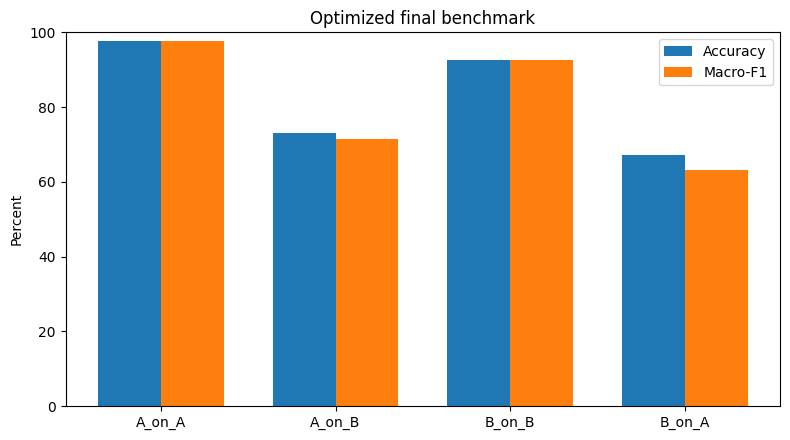

[100.0%] complete: Optimization complete in 7.7 minutes

FINAL OPTIMIZED BENCHMARK


,evaluation,accuracy,macro_f1,positive_recall,n_test
0,A_on_A,0.977083,0.977078,0.962500,480
1,A_on_B,0.731250,0.714274,0.975000,480
2,B_on_B,0.927083,0.927075,0.937500,480
3,B_on_A,0.670833,0.630834,0.341667,480



BASELINE VS OPTIMIZED


,evaluation,baseline_accuracy,optimized_accuracy,accuracy_change_pp,baseline_macro_f1,optimized_macro_f1,macro_f1_change_pp
0,A_on_A,0.9646,0.977083,1.248333,0.9646,0.977078,1.247846
1,A_on_B,0.8271,0.731250,-9.585000,0.8251,0.714274,-11.082615
2,B_on_B,0.9396,0.927083,-1.251667,0.9396,0.927075,-1.252458
3,B_on_A,0.6104,0.670833,6.043333,0.5407,0.630834,9.013393



SELECTIVE PREDICTION


,evaluation,threshold,n_total,n_answered,n_abstained,coverage,selective_risk,selective_accuracy
0,A_on_B,0.3,480,428,52,0.891667,0.245327,0.754673
1,A_on_B,0.4,480,456,24,0.950000,0.258772,0.741228
2,A_on_B,0.5,480,480,0,1.000000,0.268750,0.731250
3,B_on_A,0.3,480,398,82,0.829167,0.298995,0.701005
4,B_on_A,0.4,480,437,43,0.910417,0.313501,0.686499
5,B_on_A,0.5,480,480,0,1.000000,0.329167,0.670833



SAVED TO: /content/drive/MyDrive/friend-cxr-30/optimization
Send me optimization_summary.json and baseline_vs_optimized.csv after completion.


In [4]:
# Paste this entire cell AFTER the old FRIEND notebook has completed.
# It reuses the functions already defined in that notebook.

import gc, json, random, time
from pathlib import Path
import kagglehub
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, f1_score
from torch.cuda.amp import autocast
from torchvision import models

required = ["image_files", "find_dir", "balanced_split", "make_loaders", "predict",
            "atomic_json", "utc_now", "selective_prediction"]
missing = [name for name in required if name not in globals()]
if missing:
    raise RuntimeError(f"First run all old FRIEND notebook cells. Missing: {missing}")
if not torch.cuda.is_available():
    raise RuntimeError("Select Runtime > Change runtime type > T4 GPU, then run this cell again.")

OPT_ROOT = Path("/content/drive/MyDrive/friend-cxr-30/optimization")
RESULTS = OPT_ROOT / "results"
CHECKPOINTS = OPT_ROOT / "checkpoints"
for folder in (OPT_ROOT, RESULTS, CHECKPOINTS):
    folder.mkdir(parents=True, exist_ok=True)

DEVICE = torch.device("cuda")
GPU = torch.cuda.get_device_name(0)
GPU_GB = torch.cuda.get_device_properties(0).total_memory / 1024**3
OPT_BATCH = 32 if GPU_GB >= 14 else 16
OPT_WORKERS = 2
TUNE_EPOCHS = 3
FINAL_EPOCHS = 5
started = time.time()

SEARCH = [
    {"id":"c1", "lr":1e-4, "weight_decay":1e-4, "dropout":0.2, "unfreeze_blocks":4},
    {"id":"c2", "lr":3e-4, "weight_decay":1e-4, "dropout":0.2, "unfreeze_blocks":4},
    {"id":"c3", "lr":1e-4, "weight_decay":1e-3, "dropout":0.3, "unfreeze_blocks":6},
    {"id":"c4", "lr":3e-5, "weight_decay":1e-4, "dropout":0.3, "unfreeze_blocks":6},
]
BASELINE = {
    "A_on_A": (0.9646, 0.9646), "A_on_B": (0.8271, 0.8251),
    "B_on_B": (0.9396, 0.9396), "B_on_A": (0.6104, 0.5407),
}

def opt_progress(stage, detail, percent, status="running", **extra):
    payload = {"status":status, "stage":stage, "detail":detail,
               "overall_percent":round(float(percent),1), "updated_at_utc":utc_now(), **extra}
    atomic_json(OPT_ROOT / "optimization_progress.json", payload)
    print(f"[{percent:5.1f}%] {stage}: {detail}", flush=True)

def opt_seed():
    random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
    torch.cuda.manual_seed_all(SEED); torch.backends.cudnn.benchmark = True

def opt_train_val_split(samples):
    rng = random.Random(SEED + 99)
    by_class = {0:[], 1:[]}
    for row in samples: by_class[row[1]].append(row)
    train, val = [], []
    for label in (0, 1):
        rng.shuffle(by_class[label])
        n_val = max(1, int(0.10 * len(by_class[label])))
        val.extend(by_class[label][:n_val]); train.extend(by_class[label][n_val:])
    rng.shuffle(train); rng.shuffle(val)
    return train, val

def opt_build_model(cfg):
    model = models.mobilenet_v2(weights=models.MobileNet_V2_Weights.IMAGENET1K_V1)
    for parameter in model.features.parameters(): parameter.requires_grad = False
    model.classifier[0] = nn.Dropout(p=cfg["dropout"])
    model.classifier[1] = nn.Linear(model.last_channel, 2)
    return model.to(DEVICE)

def opt_unfreeze(model, count):
    for block in list(model.features.children())[-int(count):]:
        for parameter in block.parameters(): parameter.requires_grad = True

def opt_fit(cfg, train_samples, val_samples, epochs, label, save_best=None):
    opt_seed()
    train_loader, val_loader = make_loaders(train_samples, val_samples, OPT_BATCH, OPT_WORKERS)
    model = opt_build_model(cfg)
    optimizer = torch.optim.AdamW(model.parameters(), lr=cfg["lr"], weight_decay=cfg["weight_decay"])
    loss_fn = nn.CrossEntropyLoss()
    scaler = torch.amp.GradScaler(device="cuda", enabled=True)
    best_f1, best_state, history = -1.0, None, []
    for epoch in range(epochs):
        if epoch == 1: opt_unfreeze(model, cfg["unfreeze_blocks"])
        model.train(); loss_sum = 0.0
        for images, labels, _, _ in train_loader:
            images = images.to(DEVICE, non_blocking=True); labels = labels.to(DEVICE, non_blocking=True)
            optimizer.zero_grad(set_to_none=True)
            with autocast(enabled=True):
                loss = loss_fn(model(images), labels)
            scaler.scale(loss).backward(); scaler.step(optimizer); scaler.update()
            loss_sum += loss.item() * images.size(0)
        output = predict(model, val_loader, DEVICE)
        val_f1 = f1_score(output["labels"], output["predictions"], average="macro")
        row = {"label":label, "config_id":cfg["id"], "epoch":epoch+1,
               "train_loss":loss_sum/len(train_loader.dataset), "validation_macro_f1":val_f1}
        history.append(row)
        print(f"{label} | epoch {epoch+1}/{epochs} | loss={row['train_loss']:.4f} | val F1={val_f1:.4f}")
        if val_f1 >= best_f1:
            best_f1 = val_f1
            best_state = {key:value.detach().cpu().clone() for key,value in model.state_dict().items()}
            if save_best:
                torch.save({"config":cfg, "epoch":epoch+1, "validation_macro_f1":val_f1,
                            "model":best_state}, save_best)
    model.load_state_dict(best_state)
    return model, best_f1, history

opt_progress("setup", f"GPU={GPU}; batch_size={OPT_BATCH}", 2)
root_a = Path(kagglehub.dataset_download("paultimothymooney/chest-xray-pneumonia"))
root_b = Path(kagglehub.dataset_download("tawsifurrahman/covid19-radiography-database"))
a_normal = image_files(find_dir(root_a, ["train", "NORMAL"]))
a_positive = image_files(find_dir(root_a, ["train", "PNEUMONIA"]))
b_normal = image_files(find_dir(root_b, ["Normal", "images"]))
b_positive = image_files(find_dir(root_b, ["Lung_Opacity", "images"]))
a_pool, a_test = balanced_split(a_normal, a_positive, "A_Kermany")
b_pool, b_test = balanced_split(b_normal, b_positive, "B_COVID_Radio")
a_train, a_val = opt_train_val_split(a_pool)
b_train, b_val = opt_train_val_split(b_pool)
split_info = {"A_train":len(a_train),"A_validation":len(a_val),"A_test":len(a_test),
              "B_train":len(b_train),"B_validation":len(b_val),"B_test":len(b_test),"seed":SEED}
atomic_json(OPT_ROOT / "optimization_split_summary.json", split_info)
opt_progress("data", f"Separate validation splits ready: {split_info}", 10)

trial_file = OPT_ROOT / "optimization_trials.csv"
history_file = OPT_ROOT / "optimization_history.csv"
old = pd.read_csv(trial_file) if trial_file.exists() else pd.DataFrame()
done = set(zip(old.id, old.domain)) if len(old) else set()
trial_rows = old.to_dict("records") if len(old) else []
all_history = pd.read_csv(history_file).to_dict("records") if history_file.exists() else []
total = len(SEARCH) * 2

for cfg in SEARCH:
    for domain, tr, va in (("A",a_train,a_val),("B",b_train,b_val)):
        if (cfg["id"], domain) in done:
            print(f"Skipping saved trial {cfg['id']} domain {domain}")
            continue
        completed = len(done)
        opt_progress("search", f"{cfg['id']} on domain {domain} ({completed+1}/{total})", 10+55*completed/total)
        model, best_f1, hist = opt_fit(cfg, tr, va, TUNE_EPOCHS, f"TUNE {cfg['id']} {domain}")
        trial_rows.append({**cfg, "domain":domain, "best_validation_macro_f1":best_f1})
        all_history.extend(hist)
        pd.DataFrame(trial_rows).to_csv(trial_file, index=False)
        pd.DataFrame(all_history).to_csv(history_file, index=False)
        done.add((cfg["id"],domain)); del model; gc.collect(); torch.cuda.empty_cache()

trials = pd.DataFrame(trial_rows)
ranking = (trials.groupby(["id","lr","weight_decay","dropout","unfreeze_blocks"],as_index=False)
           .best_validation_macro_f1.mean().sort_values("best_validation_macro_f1",ascending=False))
best_id = ranking.iloc[0].id
best_cfg = next(cfg for cfg in SEARCH if cfg["id"] == best_id)
atomic_json(OPT_ROOT / "best_config.json", {**best_cfg,
    "mean_validation_macro_f1":float(ranking.iloc[0].best_validation_macro_f1),
    "selection_rule":"highest mean validation macro-F1 across datasets A and B"})
print("\nSEARCH RANKING"); display(ranking)
print("SELECTED:", best_cfg)

opt_progress("final_training", f"Training final A model with {best_id}", 68)
model_a, _, hist_a = opt_fit(best_cfg, a_train, a_val, FINAL_EPOCHS, "FINAL A",
                             CHECKPOINTS / "optimized_model_A_best.pt")
opt_progress("final_training", f"Training final B model with {best_id}", 80)
model_b, _, hist_b = opt_fit(best_cfg, b_train, b_val, FINAL_EPOCHS, "FINAL B",
                             CHECKPOINTS / "optimized_model_B_best.pt")
pd.DataFrame(hist_a+hist_b).to_csv(RESULTS / "final_training_history.csv", index=False)

def opt_evaluate(model, name, samples):
    _, data_loader = make_loaders(samples, samples, OPT_BATCH, OPT_WORKERS)
    out = predict(model, data_loader, DEVICE)
    report = classification_report(out["labels"],out["predictions"],target_names=["Normal","Positive"],
                                   output_dict=True,zero_division=0)
    row = {"evaluation":name,"accuracy":accuracy_score(out["labels"],out["predictions"]),
           "macro_f1":f1_score(out["labels"],out["predictions"],average="macro"),
           "positive_recall":report["Positive"]["recall"],"n_test":len(samples)}
    pd.DataFrame({"path":out["paths"],"label":out["labels"],"prediction":out["predictions"],
                  "p_normal":out["probabilities"][:,0],"p_positive":out["probabilities"][:,1],
                  "uncertainty":1-out["probabilities"].max(axis=1)}).to_csv(
                      RESULTS/f"optimized_predictions_{name}.csv",index=False)
    atomic_json(RESULTS/f"optimized_metrics_{name}.json", {**row,"classification_report":report,
                "confusion_matrix":confusion_matrix(out["labels"],out["predictions"]).tolist()})
    return out,row

opt_progress("evaluation", "Running all four directions", 90)
outputs, rows = {}, []
for model,name,samples in ((model_a,"A_on_A",a_test),(model_a,"A_on_B",b_test),
                           (model_b,"B_on_B",b_test),(model_b,"B_on_A",a_test)):
    outputs[name], row = opt_evaluate(model,name,samples); rows.append(row)
metrics = pd.DataFrame(rows); metrics.to_csv(RESULTS/"optimized_all_metrics.csv",index=False)

comparison = []
for row in rows:
    ba,bf = BASELINE[row["evaluation"]]
    comparison.append({"evaluation":row["evaluation"],"baseline_accuracy":ba,
        "optimized_accuracy":row["accuracy"],"accuracy_change_pp":100*(row["accuracy"]-ba),
        "baseline_macro_f1":bf,"optimized_macro_f1":row["macro_f1"],
        "macro_f1_change_pp":100*(row["macro_f1"]-bf)})
comparison = pd.DataFrame(comparison)
comparison.to_csv(RESULTS/"baseline_vs_optimized.csv",index=False)

selective = []
for name in ("A_on_B","B_on_A"):
    selective.extend(selective_prediction(name,outputs[name],OPT_ROOT))
selective = pd.DataFrame(selective)
selective.to_csv(RESULTS/"optimized_selective_prediction.csv",index=False)

fig,ax=plt.subplots(figsize=(8,4.5)); x=np.arange(4)
ax.bar(x-.18,metrics.accuracy*100,.36,label="Accuracy")
ax.bar(x+.18,metrics.macro_f1*100,.36,label="Macro-F1")
ax.set(xticks=x,xticklabels=metrics.evaluation,ylabel="Percent",title="Optimized final benchmark",ylim=(0,100))
ax.legend(); fig.tight_layout(); fig.savefig(RESULTS/"optimized_benchmark.png",dpi=180); plt.show()

elapsed=(time.time()-started)/60
summary={"status":"complete","elapsed_minutes":elapsed,"gpu":GPU,"best_config":best_cfg,
         "mean_validation_macro_f1":float(ranking.iloc[0].best_validation_macro_f1),
         "metrics":rows,"saved_folder":str(OPT_ROOT)}
atomic_json(OPT_ROOT/"optimization_summary.json",summary)
opt_progress("complete",f"Optimization complete in {elapsed:.1f} minutes",100,"complete",best_config=best_cfg)
print("\nFINAL OPTIMIZED BENCHMARK"); display(metrics)
print("\nBASELINE VS OPTIMIZED"); display(comparison)
print("\nSELECTIVE PREDICTION"); display(selective)
print(f"\nSAVED TO: {OPT_ROOT}")
print("Send me optimization_summary.json and baseline_vs_optimized.csv after completion.")

## Progress and recovery

Open `MyDrive/friend-cxr-30/progress.json` to see the current percentage, stage, elapsed time, last update, and remaining steps. Training checkpoints are saved after every epoch. If Colab disconnects, reconnect a GPU and run all cells again; the pipeline resumes from the latest checkpoint.
